# Settings

In [ ]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"

use_nsi = False #if using nsi, load nsi data in this order 1. zm 2. dc1 3. dc2
bf_matrix_paths = [
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_long_im/beamformed_apodized/008_bf_complex_IQ_zm.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_long_im/beamformed_apodized/008_bf_complex_IQ_dc1.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_long_im/beamformed_apodized/008_bf_complex_IQ_dc2.npy"

    "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_long_im/beamformed_apodized/008_bf_complex_rectangle.npy"
]
complex_bf = True

#Real data settings
using_matlab_data = False
matlab_bf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/005_mouse/001_BM.mat"
interpolate_data = True

#Filters
run_hp = False
run_SVD = False
run_hp_SVD = True

#Saving params
save_data = True
save_image = True
bf_data_path = "./data_filtered/"
folder_name = "mouse_long_im"
beamformed_filtered_matrix_name = "008_bff"#_complex_IQ"

# Imports

In [3]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import json
import os
from scipy.signal import butter, lfilter, envelope
from scipy.io import loadmat
from kneed import KneeLocator
from matplotlib.colors import LinearSegmentedColormap

# Import parameters

In [4]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [5]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [6]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.011827200000000001 m


# Create workspace

In [7]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    os.makedirs(f"{bf_data_path}{folder_name}")
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")

os.makedirs(f"{bf_data_path}{folder_name}/filtered_bf", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/images", exist_ok=True)

# Import BF matrix

In [8]:
if using_matlab_data:
    bf_matrix = loadmat(matlab_bf_data_path)
    bf_matrix = list(bf_matrix.values())[-1]

    if bf_matrix.ndim == 4:
        bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], bf_matrix.shape[2] * bf_matrix.shape[3]))
    print("Imported bf matrix with shape: ", bf_matrix.shape)
else:
    matrices_tmp = []
    for path in bf_matrix_paths:
        if not os.path.exists(path):
            raise FileNotFoundError(f"File {path} does not exist.")
        matrices_tmp.append(np.load(path))
    bf_matrix = np.concatenate(matrices_tmp, axis = 0)
    bf_matrix
    del matrices_tmp

    print("Imported bf matrix with shape: ", bf_matrix.shape)


if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported bf matrix with shape:  (600, 256, 160)


In [9]:
# bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], 20))
# bf_matrix = np.real(bf_matrix)

In [10]:
# pixel_width = params["image"]["dx"]
# pixel_height = params["image"]["dz"]
# physical_aspect = pixel_width / pixel_height

# plt.figure(figsize=(10, 8))
# plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), cmap='viridis', aspect=physical_aspect)

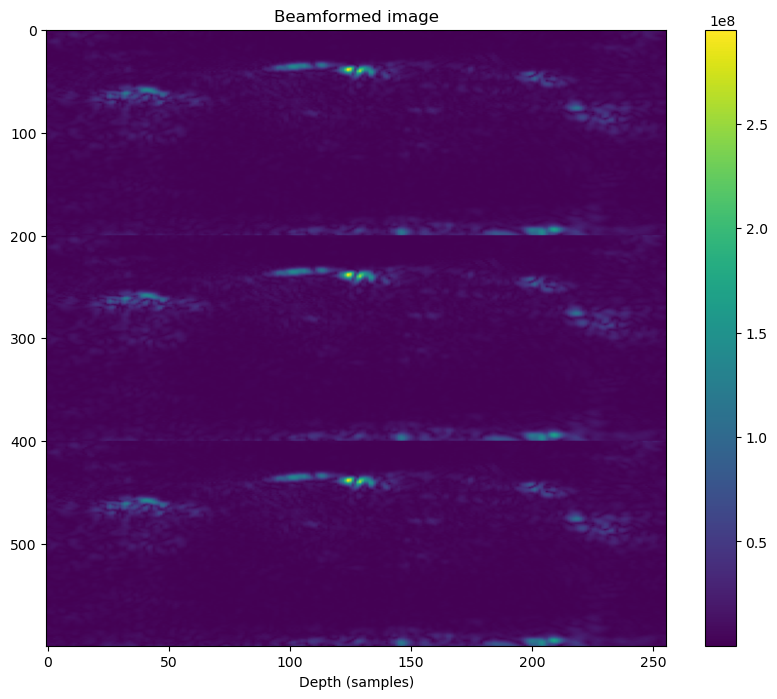

In [11]:
plt.figure(figsize=(10, 8)) 
plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Beamformed image")
plt.xlabel("Depth (samples)")
plt.show()

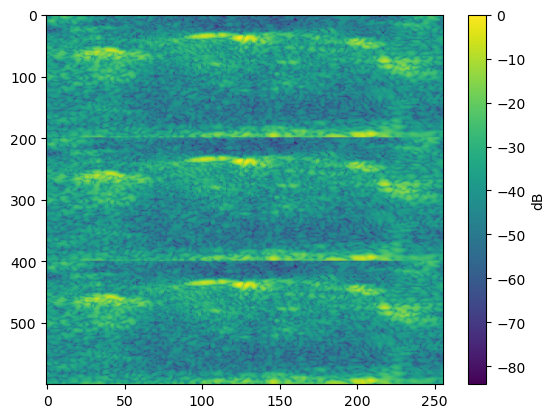

In [12]:
plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix), axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

# Save data

In [13]:
def save_beamformed_data(bf_matrix, filename, destination):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

# Filters

## SVD

In [14]:
def filter_svd(bf, nelim):
    if nelim == 0:
        return bf, None
    #get dimensions of data
    nz, nx, nt = bf.shape
    #reshape to 2D matrix (space-time)
    m = np.reshape(bf, (nz*nx, nt))
    #remove mean from each row
    m = m - np.mean(m, axis=1, keepdims=True)
    #perform SVD decomposition
    U, S, Vt = np.linalg.svd(m, full_matrices=False)
    #create diagonal matrix from singular values
    Sf = np.diag(S)
    #set smallest singular values to zero (eliminating noise)
    Sf[:nelim, :nelim] = 0
    #reconstruct filtered matrix 
    mf = U @ Sf @ Vt
    #reshape back to 3D
    bff = np.reshape(mf, (nz, nx, nt))
    #return filtered data and singular values
    return bff, S

In [15]:
if run_SVD:
    filtered_svd, S = filter_svd(bf_matrix, 10)
    plt.imshow(20 * np.log10(np.sum(np.abs(filtered_svd),axis=2) / np.max(np.sum(np.abs(filtered_svd), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.colorbar(label='dB')
    plt.title('SVD filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_svd), axis=2), f"{beamformed_filtered_matrix_name}_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_svd.png")
        
    plt.show()

## High Pass

In [16]:
def filter_hp(bf, fsam, f, nrebound):

    #subtract continuous componen
    bf  = bf -  np.mean(bf, axis=2, keepdims=True)
    #butterworth high-pass filter
    b, a = butter(3, f*0.6, 'highpass', output='ba', fs=fsam)
    #apply filter along the time dimension
    bff = lfilter(b, a, bf, axis=2)
    #the first nelim images are eliminated because the filter border effect
    if nrebound > 0:
        bff[:,:,0:nrebound] = 0
        
    return bff

In [17]:
if run_hp:    
    filtered_hp = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
    # plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')
    plt.imshow(np.sum(np.abs(filtered_hp),axis=2), aspect='auto', cmap='viridis')

    plt.colorbar(label='dB')
    plt.title('High-pass filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_hp), axis=2), f"{beamformed_filtered_matrix_name}_hp", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp.png")
        
    plt.show()

## HP + SVD

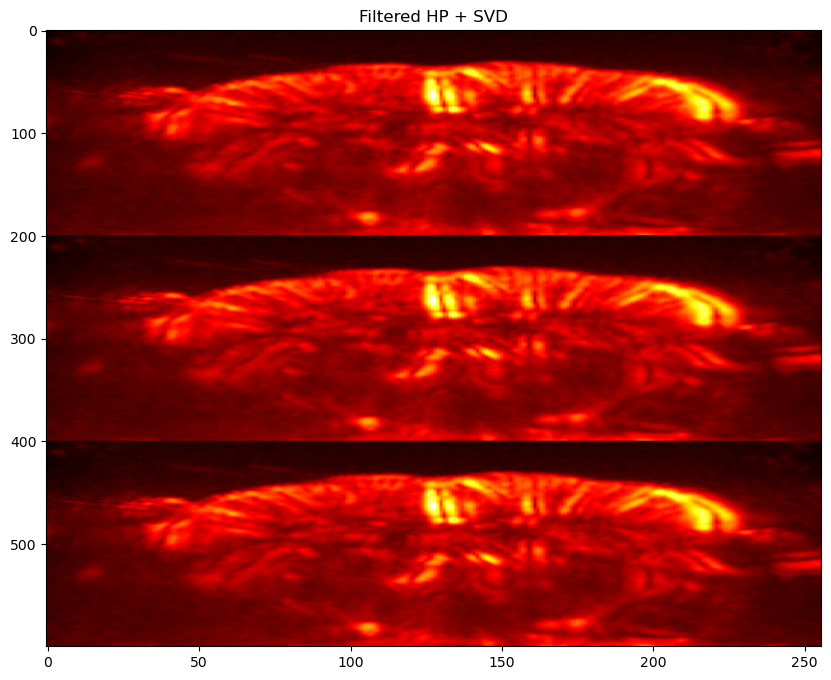

In [18]:
if run_hp_SVD:
    filtered_hp_svd = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
    filtered_hp_svd, S = filter_svd(filtered_hp_svd, 9)

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd),axis=2)), aspect='auto', cmap='hot')
    # plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    # plt.colorbar(label='Amplitude')
    plt.title(f"Filtered HP + SVD")

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_hp_svd), axis=2), f"{beamformed_filtered_matrix_name}_hp_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd.png")

    plt.show()

Optimal number of singular values to remove: 9


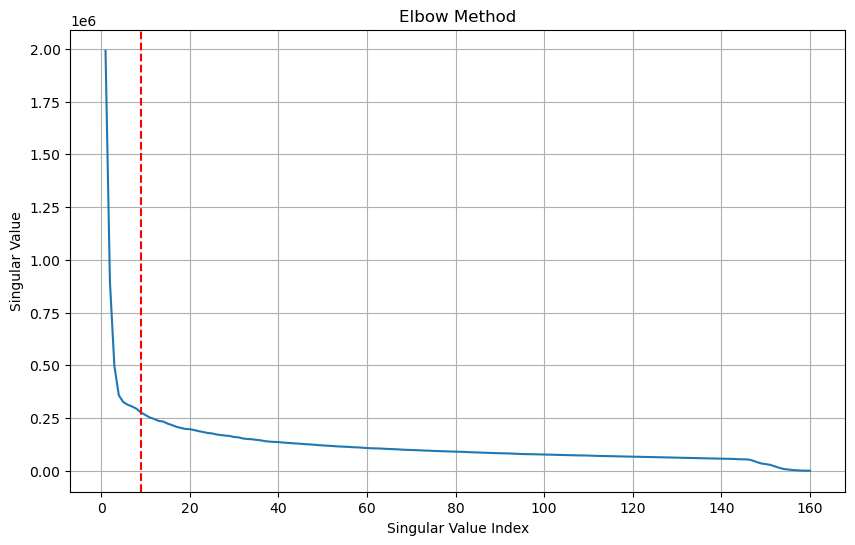

In [19]:
if run_hp_SVD:
    kneedle = KneeLocator(range(1, len(S) + 1), S, curve='convex', direction='decreasing')
    print(f"Optimal number of singular values to remove: {kneedle.elbow}")

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(S) + 1), S)
    plt.axvline(x=kneedle.elbow, color='r', linestyle='--')
    plt.title('Elbow Method')
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value')
    plt.grid()

# Phase shift

# Recombine NSI

In [20]:
def get_envelope(bf_matrix, frames, complex_arg = False):
    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution, frames))
    for i in range(0, frames):
        for j in range(0, lateral_resolution):
            if complex_arg:
                env[:,j,i] = np.abs(bf_matrix[:,j,i])
            else:
                env[:,j,i] = envelope(bf_matrix[:,j,i], residual=None)
    return env

bff_zm shape: (200, 256, 160)
bff_dc1 shape: (200, 256, 160)
bff_dc2 shape: (200, 256, 160)
Beamformed data of shape (200, 256) saved at: ./data_filtered/mouse_long_im/filtered_bf/008_bff_complex_IQ_nsi.npy


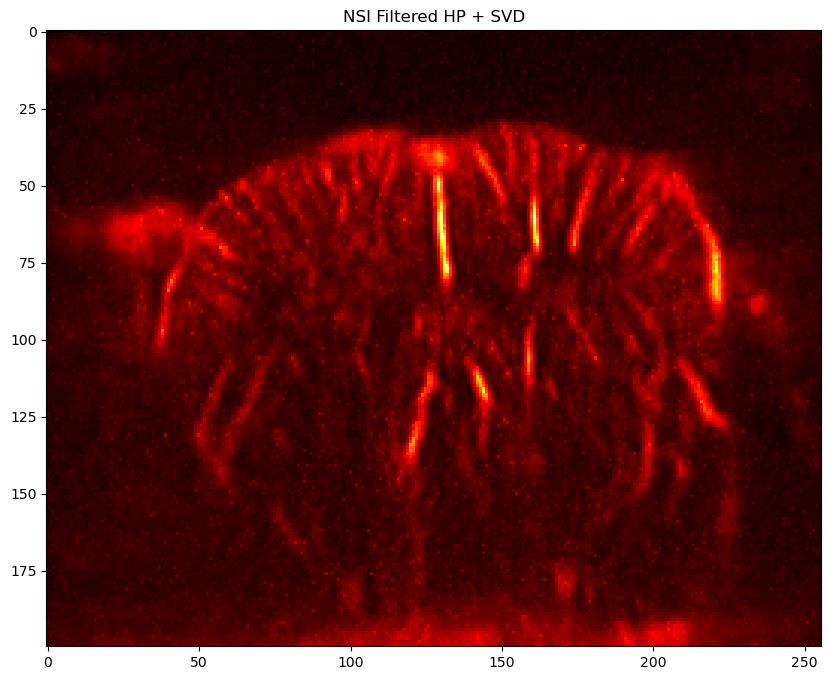

In [ ]:
#memmap_env_nsi[:,:,i] = (memmap_bf_matrix_dc1[:,:,i] + memmap_bf_matrix_dc2[:,:,i]) / 2 - memmap_bf_matrix_zm[:,:,i]

if use_nsi:
    z_limit = filtered_hp_svd.shape[0] // 3

    bff_zm = filtered_hp_svd[:z_limit,:,:]
    bff_dc1 = filtered_hp_svd[z_limit:z_limit*2,:,:]
    bff_dc2 = filtered_hp_svd[z_limit*2:,:,:]

    bff_zm_env = get_envelope(bff_zm, bff_zm.shape[2], complex_bf)
    bff_dc1_env = get_envelope(bff_dc1, bff_dc1.shape[2], complex_bf)
    bff_dc2_env = get_envelope(bff_dc2, bff_dc2.shape[2], complex_bf)
    
    print(f"bff_zm shape: {bff_zm.shape}")
    print(f"bff_dc1 shape: {bff_dc1.shape}")
    print(f"bff_dc2 shape: {bff_dc2.shape}")

    bff_nsi = (bff_dc1_env + bff_dc2_env) / 2 - bff_zm_env
    plt.figure(figsize=(10, 8))
    # plt.imshow(20 * np.log10(np.sum(np.abs(bff_nsi),axis=2) / np.max(np.sum(np.abs(bff_nsi), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')

    plt.title(f"NSI Filtered HP + SVD")

    if save_data:
        save_beamformed_data(np.sum(np.abs(bff_nsi), axis=2), f"{beamformed_filtered_matrix_name}_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")
    if save_image:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_nsi.png")

    filtered_hp_svd = bff_nsi

# Phase shifts

In [22]:
# plt.plot(np.arctan(filtered_hp_svd[:,100,70].imag / filtered_hp_svd[:,100,70].real))

instantaneous_phase = np.arctan(filtered_hp_svd.imag / filtered_hp_svd.real)

test_mat = np.zeros_like(filtered_hp_svd)

In [23]:
for i in range(0, filtered_hp_svd.shape[1]):
    for j in range(0, filtered_hp_svd.shape[0]):
        phase_shift = 0
        for k in range(filtered_hp_svd.shape[2]-1 , -1, -1):
            phase_shift -= instantaneous_phase[j,i,k] 

        test_mat[j,i,k] = 0 if phase_shift > 0 else filtered_hp_svd[j,i,k]
            

# Benchmark results

In [24]:
matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))

Signal: -27.67 dB, Noise: -38.34 dB, SNR: 10.67 dB


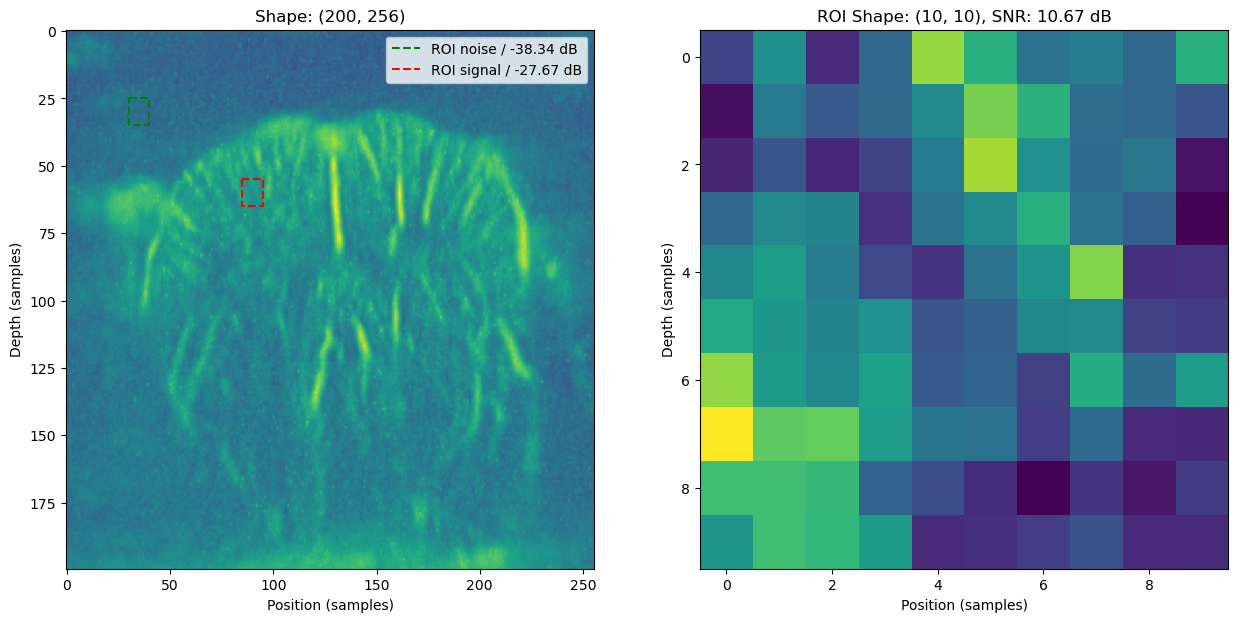

In [25]:
x0_noise = 30
z0_noise = 25
nx_noise = 10
nz_noise = 10


x0_roi = 85
z0_roi = 55
nx_roi = 10
nz_roi = 10

sub_plot_size = 1 if nx_roi == None or nz_roi == None else 2

fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

if sub_plot_size == 1:
    ax = [ax]

#define noise region of interest
noise_matrix = matrix_to_analyze[z0_noise:z0_noise+nz_noise, x0_noise:x0_noise+nx_noise]
Pnoise = np.mean(noise_matrix)
ax[0].plot([x0_noise, x0_noise+nx_noise, x0_noise+nx_noise, x0_noise, x0_noise], [z0_noise, z0_noise, z0_noise+nz_noise, z0_noise+nz_noise, z0_noise], 'g--', label=f'ROI noise / {Pnoise:.2f} dB')


ax[0].imshow(matrix_to_analyze, aspect='auto', cmap='viridis', vmin=-60, vmax=0)
ax[0].set_xlabel("Position (samples)")
ax[0].set_ylabel("Depth (samples)")
ax[0].set_title(f"Shape: {matrix_to_analyze.shape}")

data = matrix_to_analyze[z0_roi:z0_roi+nz_roi, x0_roi:x0_roi+nx_roi]
Psignal= np.mean(data)

ax[0].plot([x0_roi, x0_roi+nx_roi, x0_roi+nx_roi, x0_roi, x0_roi], [z0_roi, z0_roi, z0_roi+nz_roi, z0_roi+nz_roi, z0_roi], 'r--', label=f'ROI signal / {Psignal:.2f} dB')
ax[0].legend()

ax[1].imshow(data, aspect='auto', cmap='viridis')
ax[1].set_xlabel("Position (samples)")
ax[1].set_ylabel("Depth (samples)")

snr_db = Psignal - Pnoise

ax[1].set_title(f"ROI Shape: {data.shape}, SNR: {snr_db:.2f} dB")

print(f"Signal: {Psignal:.2f} dB, Noise: {Pnoise:.2f} dB, SNR: {snr_db:.2f} dB")

plt.show()

# Movement filters

In [26]:
def filter_movement(rf_data, frames, direction = "up"):
    filtered_rf_data = np.zeros_like(rf_data, dtype=np.complex64)
    flow_intensity_map = np.zeros((rf_data.shape[0], rf_data.shape[1]), dtype=np.float32)

    instantaneous_phase = np.angle(rf_data)

    for i in range(0, rf_data.shape[1]):    #tranducers
        for j in range(0, rf_data.shape[0]):    #samples depth
            for k in range(1 , frames):  #frames

                phase_shift = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
                if direction == "up":
                    filtered_rf_data[j,i,k] = 0 if phase_shift > 0 else rf_data[j,i,k]
                    flow_intensity_map[j,i] += np.abs(filtered_rf_data[j,i,k])
                elif direction == "down":
                    filtered_rf_data[j,i,k] = 0 if phase_shift < 0 else rf_data[j,i,k]
                    flow_intensity_map[j,i] += np.abs(filtered_rf_data[j,i,k])

    
    return filtered_rf_data, flow_intensity_map

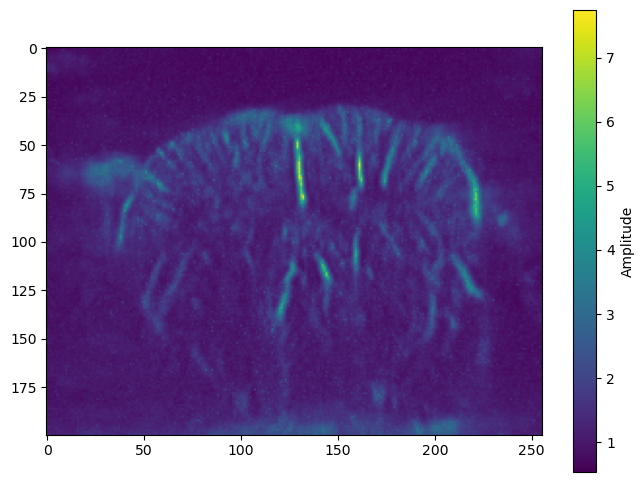

In [27]:
if complex_bf:
    filtered_hp_svd_up, flow_intensity_up = filter_movement(filtered_hp_svd, filtered_hp_svd.shape[2], "up")
    filtered_hp_svd_down,flow_intensity_down = filter_movement(filtered_hp_svd, filtered_hp_svd.shape[2], "down")

    plt.figure(figsize=(8,6))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd), axis = 2)))
    plt.colorbar(label='Amplitude')

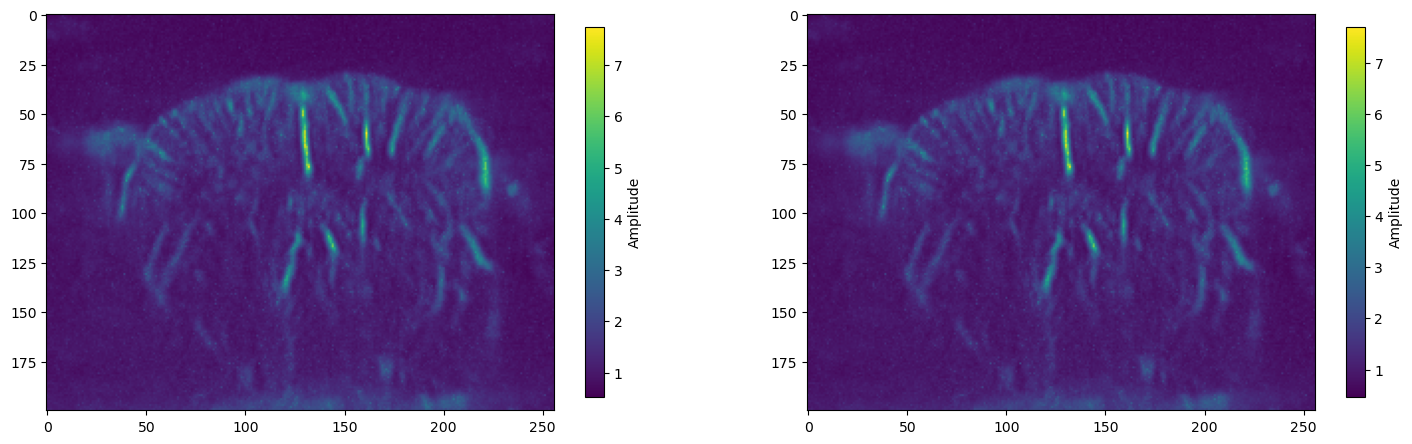

In [35]:
if complex_bf:
    fig, axes = plt.subplots(nrows= 1, ncols= 2, figsize=(18,16))
    im1 = axes[0].imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd_up), axis = 2)))#, cmap=custom_cmap)
    im2 =axes[1].imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd_down), axis = 2)))#, cmap=custom_cmap)
    fig.colorbar(im1, label='Amplitude', ax=axes[0], shrink =0.3)
    fig.colorbar(im2, label='Amplitude', ax=axes[1], shrink =0.3)

In [ ]:
# tmp = filtered_hp_svd_down + filtered_hp_svd_up
# plt.figure(figsize=(8,6))
# plt.imshow(np.sqrt(np.sum(np.abs(tmp), axis = 2)))

In [ ]:
def visualize_directional_flow(rf_data, frames):

    amplitude = np.abs(rf_data)
    instantaneous_phase = np.angle(rf_data)

    phase_shifts = np.zeros_like(rf_data)

    
    for i in range(0, rf_data.shape[1]):    #tranducers
        for j in range(0, rf_data.shape[0]):    #samples depth
            for k in range(1 , frames):  #frames

                phase_shifts[j,i,k] = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
    
    #sum all amplitudes for frame - later for intensity
    cumulative_amplitude = np.sum(amplitude, axis=2)
    cumulative_amplitude = cumulative_amplitude / np.max(cumulative_amplitude)  #norm between 0 and 1
    
    #flow image with last axis being rgb channels 
    flow_image = np.zeros((rf_data.shape[0], rf_data.shape[1], 3))
    
    #flow image making with red and blue channels
    for i in range(0, rf_data.shape[1]):    # transducers
        for j in range(0, rf_data.shape[0]):    # samples depth
            upward_sum = 0
            downward_sum = 0
            
            for k in range(1, frames):  # frames
                phase_shift = phase_shifts[j,i,k]
                signal_amplitude = amplitude[j,i,k]
                
                if phase_shift > 0:  # up movement
                    upward_sum += signal_amplitude
                else:  # down movement
                    downward_sum += signal_amplitude
            

            total = upward_sum + downward_sum
            if total > 0:
                upward_ratio = upward_sum / total #norme once more between 0 and 1
                downward_ratio = downward_sum / total
                
                intensity = cumulative_amplitude[j,i]
                flow_image[j,i,2] = downward_ratio * intensity  #blue
                flow_image[j,i,0] = upward_ratio * intensity    #red
    
    return flow_image

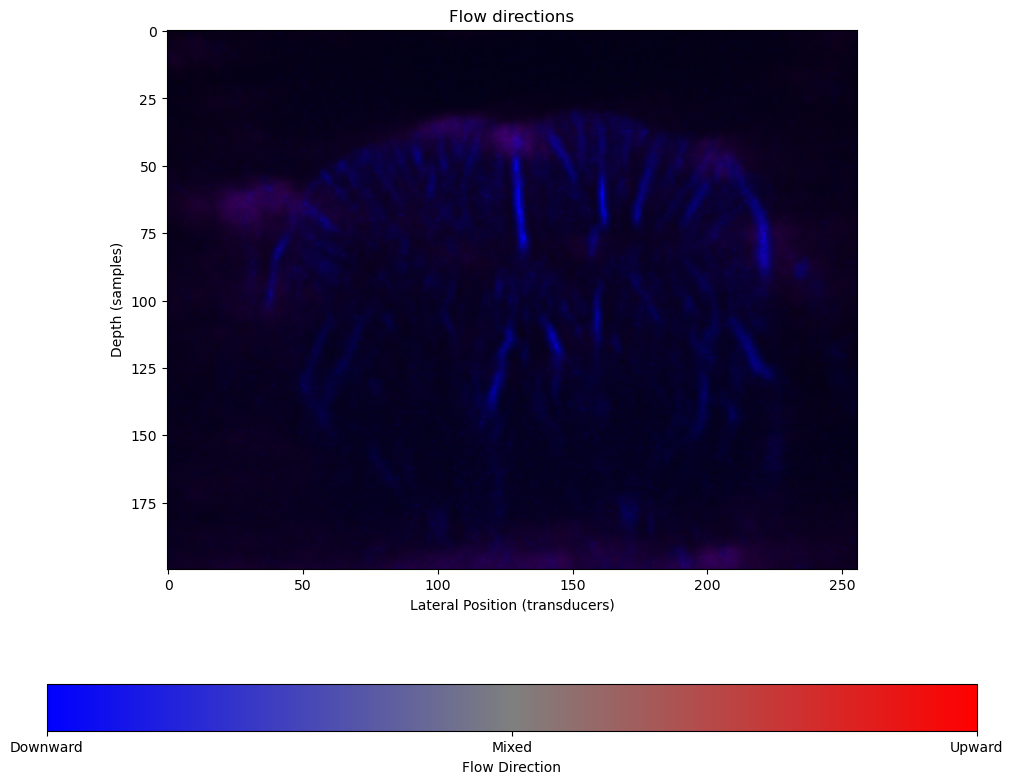

In [ ]:
if complex_bf:
    flow_image = visualize_directional_flow(filtered_hp_svd, filtered_hp_svd.shape[2])
        
    plt.figure(figsize=(12, 10))

    plt.imshow(np.sqrt(flow_image))
    plt.title("Flow directions")
    plt.xlabel("Lateral Position (transducers)")
    plt.ylabel("Depth (samples)")


    cmap_colors = [(0, 0, 1), (0.5, 0.5, 0.5), (1, 0, 0)]  #RGB color map (in RGB format)
    custom_cmap = LinearSegmentedColormap.from_list('custom', cmap_colors)

    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap),ax=plt.gca(), orientation='horizontal')
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(['Downward', 'Mixed', 'Upward'])
    cb.set_label('Flow Direction')